In [1]:
import pandas as pd 

import numpy as np

import matplotlib.pyplot as plt

import seaborn as sns

from pathlib import Path

from sklearn.metrics import silhouette_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.cluster import  KMeans   
from sklearn.decomposition import PCA

from kmodes.kmodes import KModes

import umap



PASTA_IMAGENS = Path("../../repositorio imagens/04 Modelos não supervisionados/K-means e K-modes/K_means")
PASTA_IMAGENS.mkdir(parents=True, exist_ok=True)


def salvar_figura(nome_arquivo):
    plt.gcf().savefig(PASTA_IMAGENS / nome_arquivo, dpi=150, bbox_inches="tight")

ID_COLUNA = 'ID_DOMICILIO'
PESO_COLUNA = 'PESO_AMOSTRAL'
TARGET = 'DEPRESSAO_PHQ_SIMPLIFICADO'

COLUNAS_SINTOMAS_DEPRESSAO = [
    'FREQ_PERDA_INTERESSE_2SEM',
    'FREQ_SENTIU_DEPRIMIDO_2SEM',
    'FREQ_DIFICULDADE_DORMIR_2SEM',
    'FREQ_CANSASO_2SEM',
    'FREQ_HIPOREXIA_COMPULSAO_ALIMENTAR_2SEM',
    'FREQ_AUTOAVALIACAO_NEGTIVA_2SEM',
    'FREQ_DIFICULDADE_CONCENTRACAO_2SEM',
    'MODIFICACAO_VELOCIDADE_FALA',
    'FREQ_DEPRESSAO',
    'REMEDIO_DEPRESSAO',
    'HISTORICO_DEPRESSAO',
    'INTENSIDADE_DEPRESSAO'
]

# 1. Carregar a base limpa e definir o ID como índice
df = pd.read_csv(Path("../../01 Preparação dos dados/dados/limpos/adult25_limpo.csv")).set_index(ID_COLUNA)
df["DEPRESSAO_PHQ_SIMPLIFICADO"] = ((df["SEVERIDADE_DEPRESSAO_PHQ"] != 1)&(df["SEVERIDADE_DEPRESSAO_PHQ"] != -1)).astype(int)

# 2. Eliminar os registros indefinidos no TARGET (-1 e 5)
df = df[~df[TARGET].isin([-1, 5])].copy()

# 3. Isolar Target (y), Peso Amostral e Features Preditoras (X)
y = df[TARGET]
sample_weights = df[PESO_COLUNA]
colunas_remover = [TARGET, PESO_COLUNA] + COLUNAS_SINTOMAS_DEPRESSAO
X = df.drop(columns=[col for col in colunas_remover if col in df.columns])

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Pré-processamento
num_cols = ['RAZAO_RENDA_POBREZA','IDADE']
cat_cols = [col for col in X.columns if col not in num_cols]

preprocessor_A = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'), cat_cols)
    ]
)

X_proc = preprocessor_A.fit_transform(X)

X_proc = pd.DataFrame(X_proc, columns=preprocessor_A.get_feature_names_out(), index=X.index)

X_proc.head()

,num__RAZAO_RENDA_POBREZA,num__IDADE,cat__SEXO_1,cat__SEXO_2,cat__CLASSIFICACAO_URBANO_RURAL_2,cat__CLASSIFICACAO_URBANO_RURAL_3,cat__CLASSIFICACAO_URBANO_RURAL_4,cat__REGIAO_GEOGRAFICA_2,cat__REGIAO_GEOGRAFICA_3,cat__REGIAO_GEOGRAFICA_4,...,cat__FREQUENCIA_FALHA_MEMORIA_3,cat__FREQUENCIA_FALHA_MEMORIA_4,cat__TIPO_DIFICULDADE_COGNITIVA_1,cat__TIPO_DIFICULDADE_COGNITIVA_2,cat__TIPO_DIFICULDADE_COGNITIVA_3,cat__TIPO_DIFICULDADE_COGNITIVA_4,cat__QTD_DIFICULDADE_COGNITIVA_1,cat__QTD_DIFICULDADE_COGNITIVA_2,cat__QTD_DIFICULDADE_COGNITIVA_3,cat__QTD_DIFICULDADE_COGNITIVA_4
ID_DOMICILIO,,,,,,,,,,,,,,,,,,,,,
H012128,-0.876563,0.908759,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0
H000617,-0.001807,0.696469,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
H033243,-1.323519,-1.851016,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0
H049140,0.636701,0.908759,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0
H012797,0.183360,0.059597,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0


In [3]:
def ajustar_kmeans(n_clusters, dados):
    modelo = KMeans(
        n_clusters=n_clusters,
        init='k-means++',
        n_init=10,
        max_iter=300,
        tol=1e-4,
        random_state=42,
    )
    labels = pd.Series(
        modelo.fit_predict(dados),
        index=dados.index,
        name="cluster",
    )
    inercia = modelo.inertia_
    silhouette = silhouette_score(dados, labels)
    return modelo, labels, inercia, silhouette


def plotar_composicao_target(resultado):
    contagens = pd.crosstab(resultado["cluster"], resultado["target"])
    proporcoes = contagens.div(contagens.sum(axis=1), axis=0).mul(100)

    print("Proporção (%) dentro de cada cluster:")
    print(proporcoes.round(1))

    ax = proporcoes.plot(
        kind="bar",
        stacked=True,
        figsize=(8, 5),
        color=["#4C78A8", "#F58518"],
    )

    for barras in ax.containers:
        ax.bar_label(barras, fmt="%.1f%%", label_type="center")

    ax.set(
        title="Composição do target em cada cluster",
        xlabel="Cluster",
        ylabel="Proporção dentro do cluster (%)",
    )
    ax.legend(title="Target")
    ax.set_ylim(0, 100)
    plt.xticks(rotation=0)
    plt.tight_layout()
    salvar_figura(f"composicao_target_{resultado['cluster'].nunique()}_clusters.png")
    plt.show()


km, labels, inercia, silhouettes = ajustar_kmeans(2, X_proc)


target  cluster
0       1          11376
        0           7824
1       1           2791
        0           2224
Name: count, dtype: int64
Proporção (%) dentro de cada cluster:
target      0     1
cluster            
0        77.9  22.1
1        80.3  19.7


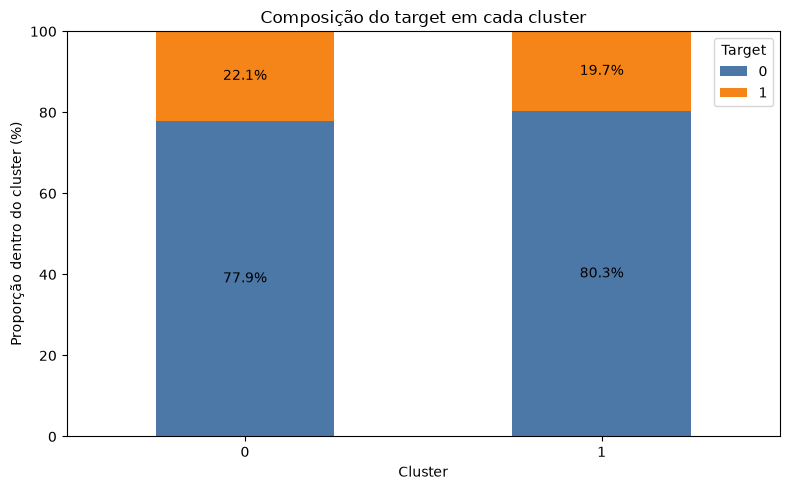

In [4]:
resultado = pd.DataFrame({
    "target": y,
    "cluster": labels,
})

print(resultado.sort_values("target").value_counts())

plotar_composicao_target(resultado)

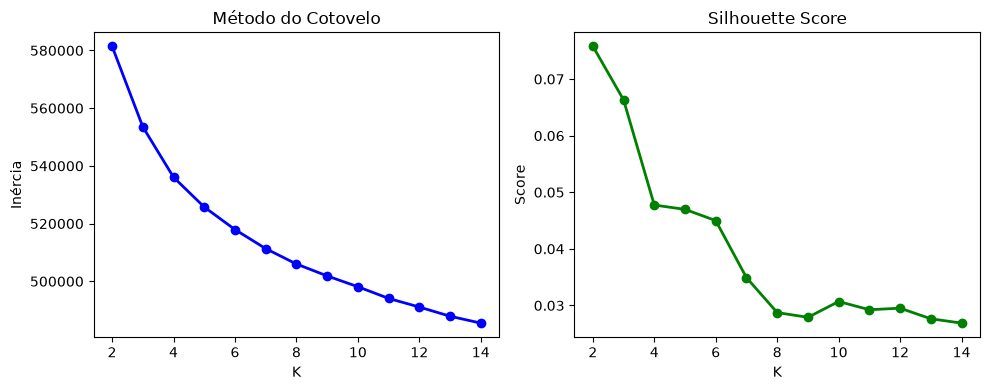

In [5]:
inercias, silhouettes = [], []
ks = range(2,15)
for k in ks:
    km, labels, inercia, silhouette = ajustar_kmeans(k, X_proc)
    inercias.append(inercia)
    silhouettes.append(silhouette)



# Plotar diagnóstico
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
ax1.plot(ks, inercias, 'bo-', linewidth=2)
ax1.set_title('Método do Cotovelo'); ax1.set_xlabel('K'); ax1.set_ylabel('Inércia')
ax2.plot(ks, silhouettes, 'go-', linewidth=2)
ax2.set_title('Silhouette Score'); ax2.set_xlabel('K'); ax2.set_ylabel('Score')
plt.tight_layout(); salvar_figura("diagnostico_k.png"); plt.show()


Proporção (%) dentro de cada cluster:
target      0     1
cluster            
0        35.1  64.9
1        87.2  12.8
2        94.9   5.1


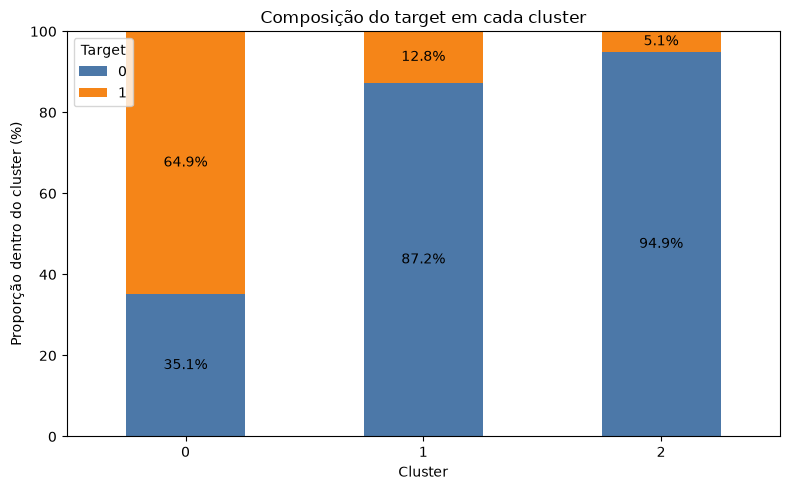

In [6]:
km, labels, inercia, silhouettes = ajustar_kmeans(3, X_proc)


resultado = pd.DataFrame({
    "target": y,
    "cluster": labels,
})

plotar_composicao_target(resultado)

Proporção (%) dentro de cada cluster:
target      0     1
cluster            
0        31.4  68.6
1        93.7   6.3
2        86.3  13.7
3        93.5   6.5


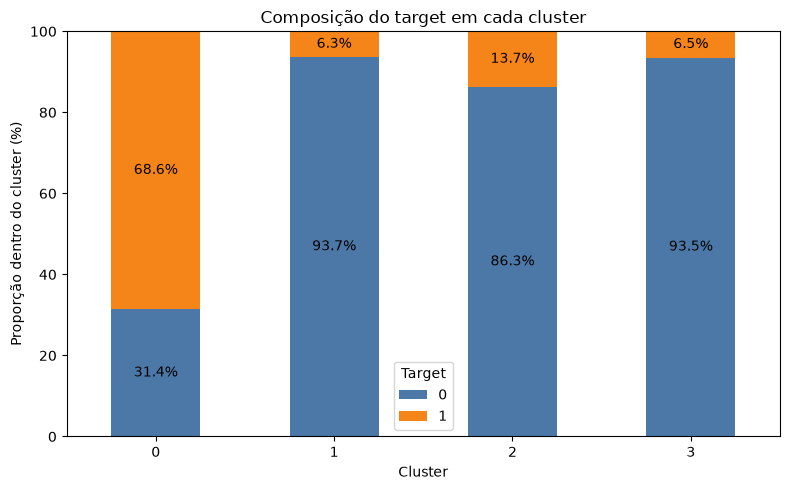

In [7]:
km, labels, inercia, silhouettes = ajustar_kmeans(4, X_proc)


resultado = pd.DataFrame({
    "target": y,
    "cluster": labels,
})

plotar_composicao_target(resultado)

Proporção (%) dentro de cada cluster:
target      0     1
cluster            
0        93.6   6.4
1        40.5  59.5
2        94.6   5.4
3        34.7  65.3
4        95.0   5.0


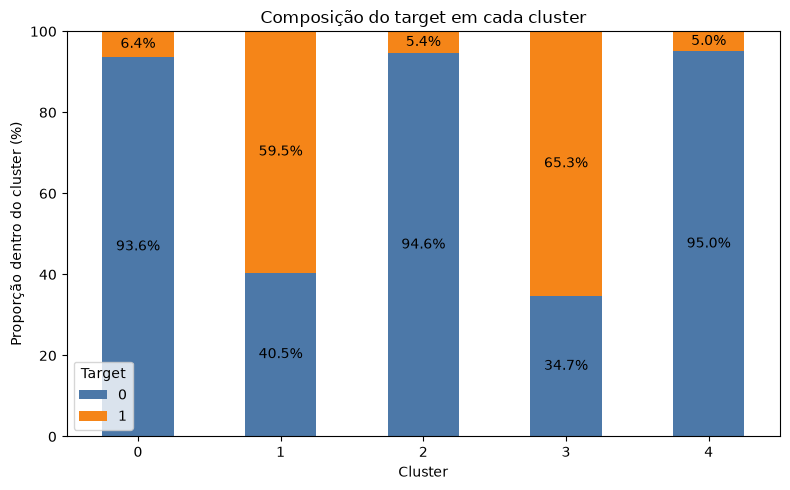

In [8]:
km, labels, inercia, silhouettes = ajustar_kmeans(5, X_proc)


resultado = pd.DataFrame({
    "target": y,
    "cluster": labels,
})

plotar_composicao_target(resultado)

2
0.17800018747425467


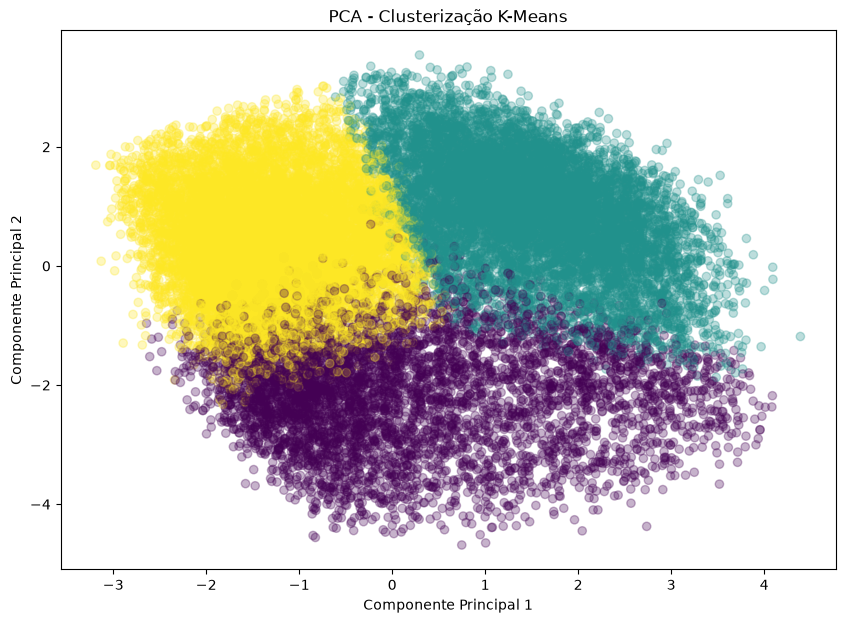

In [9]:
km, labels, inercia, silhouettes = ajustar_kmeans(3, X_proc)


resultado = pd.DataFrame({
    "target": y,
    "cluster": labels,
})

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_proc)

print(pca.n_components_)
print(pca.explained_variance_ratio_.sum())

plt.figure(figsize=(10, 7))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    alpha=0.3,
    c=resultado["cluster"]
)

plt.title("PCA - Clusterização K-Means")

plt.xlabel("Componente Principal 1")
plt.ylabel("Componente Principal 2")

salvar_figura("pca_clusters.png")
plt.show()


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


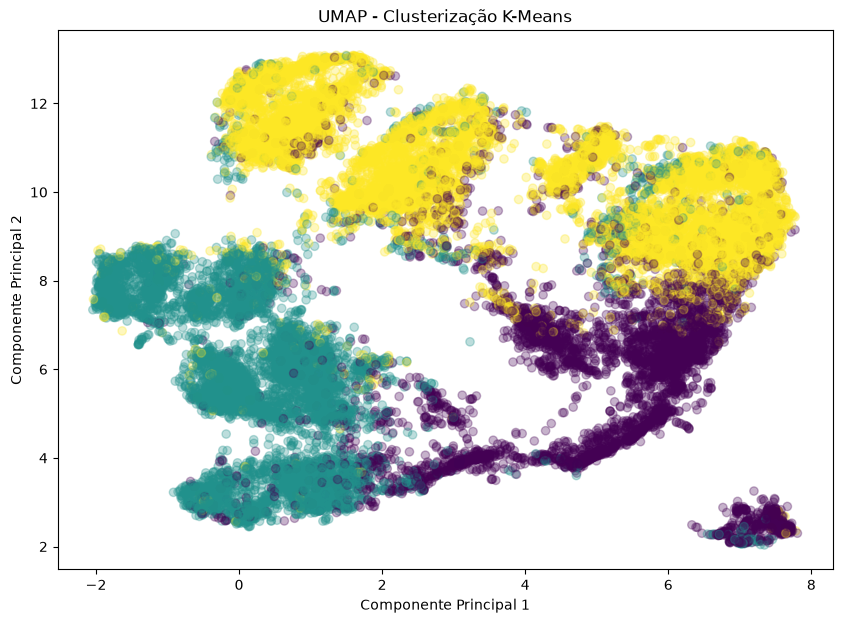

In [10]:
reducer = umap.UMAP(n_neighbors=5, min_dist=0.01, random_state=42)
X_umap = reducer.fit_transform(X_proc)

X_umap.shape

plt.figure(figsize=(10, 7))

plt.scatter(
    X_umap[:, 0],
    X_umap[:, 1],
    alpha=0.3,
    c=resultado["cluster"]
)

plt.title("UMAP - Clusterização K-Means")

plt.xlabel("Componente Principal 1")
plt.ylabel("Componente Principal 2")

salvar_figura("umap_clusters.png")
plt.show()

In [11]:
X_cluster = X.join(labels.rename("cluster"))
coluna_num = ["IDADE"]
colunas_cat = [
    "TIPO_DIFICULDADE_COGNITIVA",
    "QTD_DIFICULDADE_COGNITIVA",
    "RAZAO_RENDA_POBREZA",
    "FREQ_SOLITARIO",
    "FREQUENCIA_FALHA_MEMORIA",
    "SUPORTE_SOCIAL",
    "LIMITACAO_TRABALHO_POR_SAUDE",
    "DOR_CRONICA",
    "DEFICIENTE",
    "ESTRESSE_FINANCEIRO_MEDICO",
    "AUTOAVALIACAO_SAUDE_GERAL",
]

def primeira_moda(coluna):
    modas = coluna.mode()
    return modas.iloc[0] if not modas.empty else pd.NA

cluster_profile_cat = (
    X_cluster.groupby("cluster")[colunas_cat]
    .agg(primeira_moda)
)
cluster_profile_num = (
    X_cluster.groupby("cluster")[coluna_num]
    .mean()
    .round(2)
)

cluster_profile_num =  (cluster_profile_num - cluster_profile_num.mean()) / cluster_profile_num.std()
cluster_profile = pd.concat([cluster_profile_cat, cluster_profile_num], axis=1)
print(cluster_profile)


         TIPO_DIFICULDADE_COGNITIVA  QTD_DIFICULDADE_COGNITIVA  \
cluster                                                          
0                                 4                          2   
1                                 4                          1   
2                                 4                          1   

         RAZAO_RENDA_POBREZA  FREQ_SOLITARIO  FREQUENCIA_FALHA_MEMORIA  \
cluster                                                                  
0                       12.0               3                         4   
1                       12.0               1                         4   
2                       12.0               1                         4   

         SUPORTE_SOCIAL  LIMITACAO_TRABALHO_POR_SAUDE  DOR_CRONICA  \
cluster                                                              
0                     4                             2            2   
1                     5                             2            2   
2                 

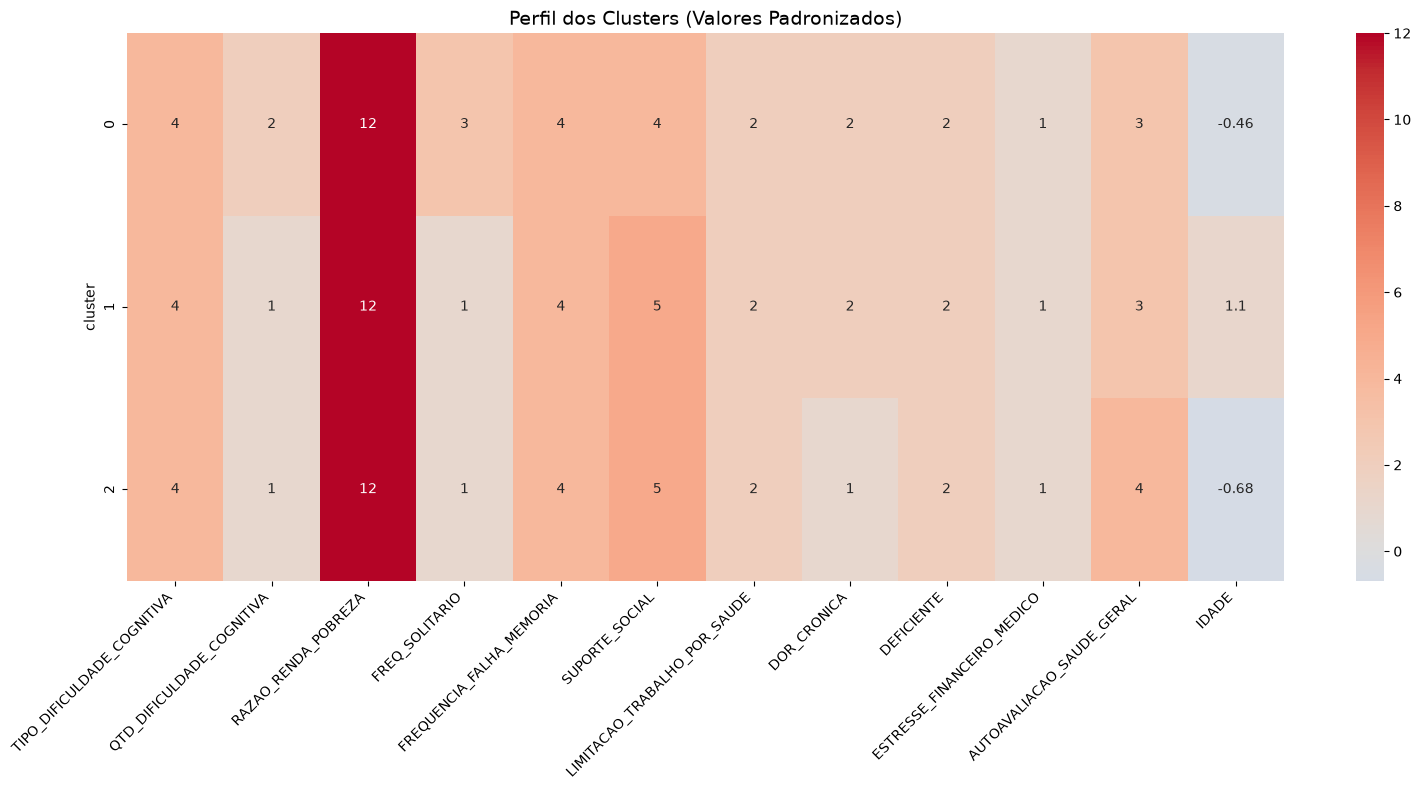

In [12]:
plt.figure(figsize=(16, 8))

sns.heatmap(
    cluster_profile,
    annot=True,
    cmap="coolwarm",
    center=0
)

plt.title(
    "Perfil dos Clusters (Valores Padronizados)",
    fontsize=14
)

plt.xticks(
    rotation=45,
    ha="right"
)

plt.tight_layout()

salvar_figura("perfil_clusters.png")
plt.show()
